# Сравнение метрик для различных LLM

In [8]:
prompt = '''Ты — модель для структурированного извлечения данных из финансовых документов.
Тебе передаётся текст документа в формате Markdown, полученный после OCR скана
(возможны ошибки распознавания, переносы строк, HTML-теги <br>, таблицы Markdown).

Твоя задача:
1. Извлечь ключевые данные документа.
2. Привести их к строго заданной структуре JSON.
3. Ничего не выдумывать: если данных нет — ставь null.
4. Вернуть ТОЛЬКО валидный JSON, без комментариев и пояснений.

====================================================
СТРУКТУРА И ТРЕБОВАНИЯ К JSON
====================================================

{
  "document": {
    "document_type": string,
    "document_number": string,
    "document_date": string (YYYY-MM-DD),
    "due_date": string (YYYY-MM-DD),
    "currency": string,
    "total_amount": number
  },

  "seller": {
    "legal_name": string,
    "inn": string,
    "kpp": string | null,
    "bank_account": string | null,
    "bank_bik": string | null,
    "bank_corr_account": string | null
  },

  "buyer": {
    "legal_name": string,
    "inn": string,
    "kpp": string | null
  },

  "contract_basis": {
    "basis_text": string | null,
    "contract_number": string | null,
    "contract_date": string (YYYY-MM-DD) | null
  },

  "items": [
    {
      "line_no": number,
      "description": string,
      "quantity": number,
      "unit": string,
      "price": number,
      "amount": number
    }
  ],

  "tax": {
    "vat_rate": number | null,
    "vat_amount": number | null,
    "vat_included": boolean | null
  },

  "payment": {
    "payment_purpose": string | null,
    "recipient_account": string | null,
    "recipient_bik": string | null,
    "recipient_corr_account": string | null
  },

  "system_meta": {
    "status": "issued",
    "source": "ocr"
  }
}

====================================================
ПРАВИЛА ИЗВЛЕЧЕНИЯ
====================================================

- Используй ИНН как основной идентификатор стороны.
- Денежные суммы приводи к числу с точкой в качестве разделителя.
- Если НДС указан как «Без НДС» — vat_rate = 0, vat_amount = 0, vat_included = false.
- Если указано «в т.ч. НДС» — vat_included = true.
- Дату извлекай из заголовка документа.
- Срок оплаты ищи по фразам:
  «Оплатить не позднее», «Счет действителен до», «Срок оплаты».
- Табличную часть извлекай построчно, сохраняя порядок.
- HTML-теги (<br>) и переносы строк в описаниях объединяй в один текст.

====================================================
ВХОДНЫЕ ДАННЫЕ
====================================================

{{DOCUMENT_MARKDOWN}}

====================================================
ВЫХОД
====================================================

Верни только JSON, строго соответствующий описанной структуре.
'''

### Обращение к модели

In [9]:
import ollama
import os
import time
max_generation_time = 200

def get_llm_answer(text: str, model_name: str, image_path: str|None = None, is_print_stream=False):
    text = prompt.replace("{{DOCUMENT_MARKDOWN}}", text)
    messege = {"role": "user", "content": text}
    if image_path:
        messege["image"] = image_path
        
    response_stream = ollama.chat(
    model=model_name,
    messages=[messege],
    stream=True,
    options={"temperature": 0.1}
)

    st = time.time()
    result = ""
    for chunk in response_stream:
        if "message" in chunk and "content" in chunk["message"]:
            token = chunk["message"]["content"]
            if is_print_stream:
                print(token, end="", flush=True)
            result += token
        if time.time() - st > max_generation_time:
            break
    generated_time = time.time() - st
    return {"result_text": result, "generated_time": generated_time}

### Получение данных Ground Truth разметки

In [10]:
import pandas as pd
test_data_path = "test_data"

input_paths = []
gt_paths = []
for file_path in os.listdir(test_data_path):
    if ".md" in file_path:
        file_path = os.path.join(test_data_path, file_path)
        gt_file_path = file_path.replace(".md", "_gt.json")
        input_paths.append(file_path)
        gt_paths.append(gt_file_path)


test_data = pd.DataFrame.from_dict({"input_path": input_paths, "gt_path": gt_paths})

In [11]:
test_data

,input_path,gt_path
0,test_data\168935.md,test_data\168935_gt.json
1,test_data\171672.md,test_data\171672_gt.json
2,test_data\photo_2025-12-19_06-38-24.md,test_data\photo_2025-12-19_06-38-24_gt.json
3,test_data\photo_2025-12-19_06-38-38.md,test_data\photo_2025-12-19_06-38-38_gt.json
4,test_data\photo_2025-12-19_06-38-41.md,test_data\photo_2025-12-19_06-38-41_gt.json
5,test_data\photo_2025-12-19_06-38-43.md,test_data\photo_2025-12-19_06-38-43_gt.json
6,test_data\photo_2025-12-19_06-38-46.md,test_data\photo_2025-12-19_06-38-46_gt.json
7,test_data\photo_2025-12-19_06-38-49.md,test_data\photo_2025-12-19_06-38-49_gt.json
8,test_data\Счет_на_оплату_№_315_от_15_сентября_...,test_data\Счет_на_оплату_№_315_от_15_сентября_...
9,test_data\Счет_на_оплату_№_650_от_15_сентября_...,test_data\Счет_на_оплату_№_650_от_15_сентября_...


### Получение вывода всех LLM

In [19]:
from tqdm import tqdm
def get_all_llm_answers(test_data: pd.DataFrame, model_name: str):
    llm_answers = []
    for i in tqdm(range(len(test_data))):
        row = test_data.iloc[i]
        input_path = row["input_path"]
        answer_save_path = os.path.join("models_answer", model_name.replace(":", "_").replace("-", "_") + "___" + row["gt_path"].replace("test_data\\", "")).replace("_gt", "")
                                
        
        with open(input_path, encoding="utf-8") as f:
            file_data = f.read()
        current_answer = get_llm_answer(file_data, model_name)
        llm_answers.append(current_answer)
        with open(answer_save_path, "w", encoding="utf8") as f:
            f.write(current_answer["result_text"])
    return llm_answers
    

In [20]:
gemma_3_1b_answers = get_all_llm_answers(test_data, "gemma3:1b")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [00:48<00:00,  4.43s/it]


In [21]:
gemma_3_4b_answers = get_all_llm_answers(test_data, "gemma3:4b-it-qat")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [03:23<00:00, 18.54s/it]


In [22]:
gemma_3_answers = get_all_llm_answers(test_data, "gemma3:12b")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [18:49<00:00, 102.65s/it]


In [23]:
qwen3_4b_answers = get_all_llm_answers(test_data, "qwen3:4b")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [16:54<00:00, 92.27s/it]


In [24]:
qwen3_8b_answers = get_all_llm_answers(test_data, "qwen3:8b")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [08:36<00:00, 46.98s/it]


In [47]:
gpt_oss_20b = get_all_llm_answers(test_data, "gpt-oss:20b-cloud")

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [03:46<00:00, 20.56s/it]


In [48]:
results_dict = {"qwen3:8b": qwen3_8b_answers,
                "gemma3-4b-it": gemma_3_4b_answers,
                "gemma3:12b": gemma_3_answers,
                "gemma3:1b": gemma_3_1b_answers,
               "qwen3:4b": qwen3_4b_answers,
               "gpt-oss:20b": gpt_oss_20b}


In [49]:
import json
from typing import Any, Dict, Tuple
from collections import Counter
from math import isclose

import pandas as pd

def flatten_json(data: Any, parent_key: str = '', sep: str = '.') -> Dict[str, Any]:
    """Рекурсивно разворачивает JSON в плоский словарь {путь: значение}"""
    items = []
    if isinstance(data, dict):
        for k, v in data.items():
            new_key = f"{parent_key}{sep}{k}" if parent_key else k
            items.extend(flatten_json(v, new_key, sep=sep).items())
    elif isinstance(data, list):
        for i, v in enumerate(data):
            new_key = f"{parent_key}{sep}{i}"
            items.extend(flatten_json(v, new_key, sep=sep).items())
    else:
        items.append((parent_key, data))
    return dict(items)

def compare_items_table(gt_items: list, pred_items: list) -> Dict[str, float]:
        """Сравнение таблицы товаров (items)"""
        if not gt_items:
            return {"recall": 1.0, "precision": 1.0, "accuracy": 1.0}
        if not pred_items:
            return {"recall": 0, "precision": 0, "accuracy": 0}
    
        gt_flat = [flatten_json(it) for it in gt_items]
        pred_flat = [flatten_json(it) for it in pred_items]
    
        gt_keys = set().union(*[it.keys() for it in gt_flat])
        pred_keys = set().union(*[it.keys() for it in pred_flat])
    
        true_keys = gt_keys & pred_keys
        recall = len(true_keys) / len(gt_keys)
        precision = len(true_keys) / len(pred_keys) if pred_keys else 1.0
    
        total_correct = 0
        total_possible = 0
        for g, p in zip(gt_flat, pred_flat):
            for k in true_keys:
                if k in g and k in p and str(g[k]).strip() == str(p[k]).strip():
                    total_correct += 1
                total_possible += 1
        accuracy = total_correct / total_possible if total_possible else 1.0
    
        return {"recall": recall, "precision": precision, "accuracy": accuracy}

def compare_jsons(gt: Dict, pred: Dict) -> Dict[str, float]:
    """Сравнивает два JSON с учётом вложенности и считает метрики"""
    gt_flat = flatten_json(gt)
    pred_flat = flatten_json(pred)

    gt_keys = set(gt_flat.keys())
    pred_keys = set(pred_flat.keys())

    true_positives = len(gt_keys & pred_keys)
    recall_keys = true_positives / len(gt_keys) if gt_keys else 1.0
    precision_keys = true_positives / len(pred_keys) if pred_keys else 1.0
    f1_keys = (2 * precision_keys * recall_keys) / (precision_keys + recall_keys + 1e-9)

    matched_keys = gt_keys & pred_keys
    correct_values = 0
    for key in matched_keys:
        v1, v2 = gt_flat[key], pred_flat[key]
        if isinstance(v1, (int, float)) and isinstance(v2, (int, float)):
            if isclose(v1, v2, rel_tol=1e-3, abs_tol=1e-3):
                correct_values += 1
        elif str(v1).strip() == str(v2).strip():
            correct_values += 1

    accuracy_values = correct_values / len(matched_keys) if matched_keys else 1.0

    valid_pred = isinstance(pred, dict)

    tree_distance = 1 - (true_positives / max(len(gt_keys | pred_keys), 1))
    metrics = {
        "valid_json": 1.0 if valid_pred else 0.0,
        "recall_keys": recall_keys,
        "precision_keys": precision_keys,
        "f1_keys": f1_keys,
        "accuracy_values": accuracy_values,
        "tree_distance": tree_distance
    }
    try:
        metrics.update({f"items_{k}": v for k, v in compare_items_table(gt["items"], pred["items"]).items()})
    except:
        metrics.update({f"items_{k}": v for k, v in {"recall": 0, "precision": 0, "accuracy": 0}.items()})

    try:
        metrics.update(compare_important_fields(gt, pred))
    except:
        metrics.update({
            "document_match_pct": 0.0,
            "seller_match_pct": 0.0,
            "buyer_match_pct": 0.0
        })


    return metrics


def compare_important_fields(
    gt: Dict,
    pred: Dict,
    sections=("document", "seller", "buyer")
) -> Dict[str, float]:
    """
    Считает процент совпадений значений для важных полей
    внутри document, seller, buyer
    """
    results = {}

    for section in sections:
        gt_section = gt.get(section, {})
        pred_section = pred.get(section, {})

        if not isinstance(gt_section, dict) or not gt_section:
            results[f"{section}_match_pct"] = 1.0
            continue

        total = 0
        correct = 0

        for key, gt_value in gt_section.items():
            total += 1
            pred_value = pred_section.get(key, None)

            if isinstance(gt_value, (int, float)) and isinstance(pred_value, (int, float)):
                if isclose(gt_value, pred_value, rel_tol=1e-3, abs_tol=1e-3):
                    correct += 1
            elif gt_value is None and pred_value is None:
                correct += 1
            elif str(gt_value).strip() == str(pred_value).strip():
                correct += 1

        results[f"{section}_match_pct"] = correct / total if total else 1.0

    return results


In [50]:
from json_repair import repair_json
metrics_results_dict = {k: [] for k in results_dict.keys()}
a = 0
for model_name, model_answers in results_dict.items():
    for model_answer, gt_pred_json_path in zip(model_answers, list(test_data["gt_path"])):
        with open(gt_pred_json_path, encoding="utf-8") as f:
            gt_pred_json = f.read()
        a += 1
        model_text, model_generated_time = model_answer["result_text"], model_answer["generated_time"]
        model_json = repair_json(model_text)
        if len(model_json) < 100:
            mpdel_pred = {}
        else:
            model_pred = json.loads(model_json)

        gt_pred = json.loads(gt_pred_json)
        metrics_results_dict[model_name].append(compare_jsons(gt_pred, model_pred))

from collections import Counter

summed_metrics = {
    model: dict(sum((Counter(m) for m in metrics_list), Counter()))
    for model, metrics_list in metrics_results_dict.items()
}

In [51]:
summed_metrics

{'qwen3:8b': {'valid_json': 11.0,
  'recall_keys': 10.091648189209165,
  'precision_keys': 10.450933908045977,
  'f1_keys': 10.257376368811745,
  'accuracy_values': 7.707942081498958,
  'items_recall': 9.833333333333334,
  'items_precision': 10.2,
  'items_accuracy': 8.133333333333333,
  'document_match_pct': 7.999999999999998,
  'seller_match_pct': 5.666666666666667,
  'buyer_match_pct': 7.666666666666667,
  'tree_distance': 1.121147600144352},
 'gemma3-4b-it': {'valid_json': 11.0,
  'recall_keys': 10.116777531411676,
  'precision_keys': 10.301913875598087,
  'f1_keys': 10.201148010013094,
  'accuracy_values': 8.191547049441787,
  'items_recall': 10.166666666666666,
  'items_precision': 10.2,
  'items_accuracy': 9.35959595959596,
  'document_match_pct': 9.0,
  'seller_match_pct': 6.333333333333333,
  'buyer_match_pct': 9.666666666666668,
  'tree_distance': 1.0060876410390973},
 'gemma3:12b': {'valid_json': 11.0,
  'recall_keys': 10.657501847745749,
  'precision_keys': 10.8260869565217

## Вывод графиков с метриками

In [62]:
from math import isclose
from typing import Dict

IMPORTANT_SECTIONS = ("document", "seller", "buyer")


def compare_one_document_verbose(
    gt: Dict,
    pred: Dict,
    tol: float = 1e-3
):
    print("=" * 80)
    print("СРАВНЕНИЕ ВАЖНЫХ ПОЛЕЙ (PRED → GT)")
    print("=" * 80)

    total_fields = 0
    correct_fields = 0

    for section in IMPORTANT_SECTIONS:
        gt_section = gt.get(section, {})
        pred_section = pred.get(section, {})

        print(f"\n[{section.upper()}]")

        if not isinstance(gt_section, dict) or not gt_section:
            print("  (нет эталонных данных)")
            continue

        for key, gt_value in gt_section.items():
            pred_value = pred_section.get(key, None)
            total_fields += 1

            match = False
            if isinstance(gt_value, (int, float)) and isinstance(pred_value, (int, float)):
                match = isclose(gt_value, pred_value, rel_tol=tol, abs_tol=tol)
            elif gt_value is None and pred_value is None:
                match = True
            else:
                match = str(gt_value).strip() == str(pred_value).strip()

            if match:
                correct_fields += 1
                status = "OK"
            else:
                status = "MISS"

            print(
                f"  {key:25s} | "
                f"{str(pred_value):30s} → {str(gt_value):30s} [{status}]"
            )

    match_pct = correct_fields / total_fields if total_fields else 1.0

    print("\n" + "=" * 80)
    print("МЕТРИКИ ДЛЯ ДОКУМЕНТА")
    print("=" * 80)
    print(f"Всего полей:        {total_fields}")
    print(f"Совпадений:         {correct_fields}")
    print(f"Процент совпадений: {match_pct:.3f}")
    print("=" * 80)

    return {
        "total_fields": total_fields,
        "correct_fields": correct_fields,
        "important_fields_match_pct": match_pct
    }
def print_one_document_metrics_comparasion(model_name="gemma3-4b-it", document_number=0):   
    model_answer = results_dict[model_name][document_number]
    gt_path = test_data["gt_path"].iloc[document_number]
    
    with open(gt_path, encoding="utf-8") as f:
        gt = json.loads(f.read())
    
    model_json_text = repair_json(model_answer["result_text"])
    pred = json.loads(model_json_text) if len(model_json_text) > 100 else {}
    
    metrics = compare_one_document_verbose(gt, pred)

In [64]:
print_one_document_metrics_comparasion(document_number=0)
print("+" * 100)
print_one_document_metrics_comparasion(document_number=1)
print("+" * 100)
print_one_document_metrics_comparasion(document_number=2)

СРАВНЕНИЕ ВАЖНЫХ ПОЛЕЙ (PRED → GT)

[DOCUMENT]
  document_type             | СЧЁТ                           → Счёт на оплату                 [MISS]
  document_number           | 2/168935                       → 2/168935                       [OK]
  document_date             | 2025-09-16                     → 2025-09-16                     [OK]
  due_date                  | 2025-09-26                     → 2025-09-19                     [MISS]
  currency                  | RUB                            → RUB                            [OK]
  total_amount              | 292050.0                       → 292050.0                       [OK]

[SELLER]
  legal_name                | ООО ТД "Промэлектроника"       → ООО ТД "Промэлектроника"       [OK]
  inn                       | 6659197470                     → 6659197470                     [OK]
  kpp                       | 667801001                      → 667801001                      [OK]
  bank_account              | 407028104002800082

<Figure size 640x480 with 0 Axes>

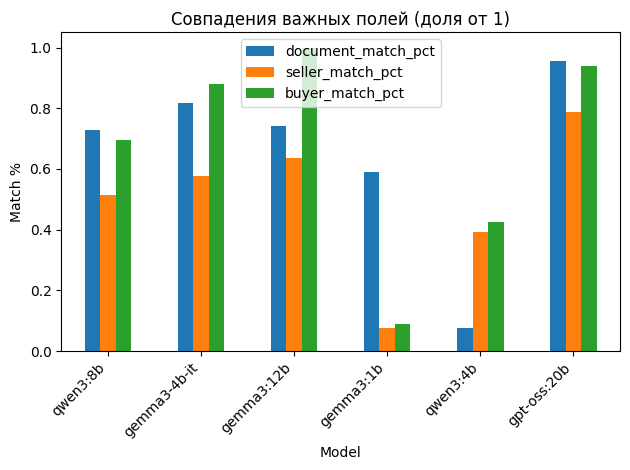

<Figure size 640x480 with 0 Axes>

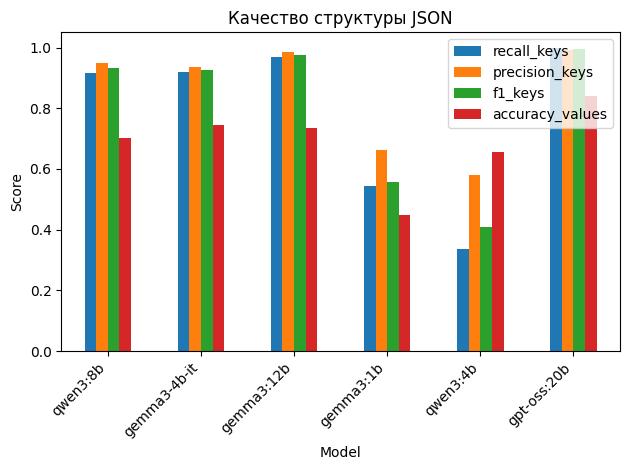

<Figure size 640x480 with 0 Axes>

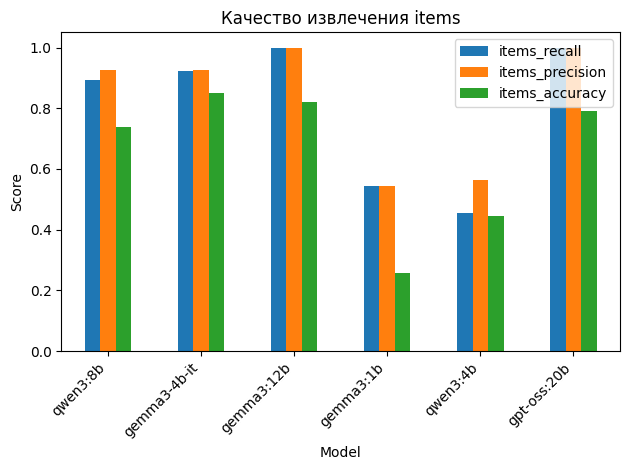

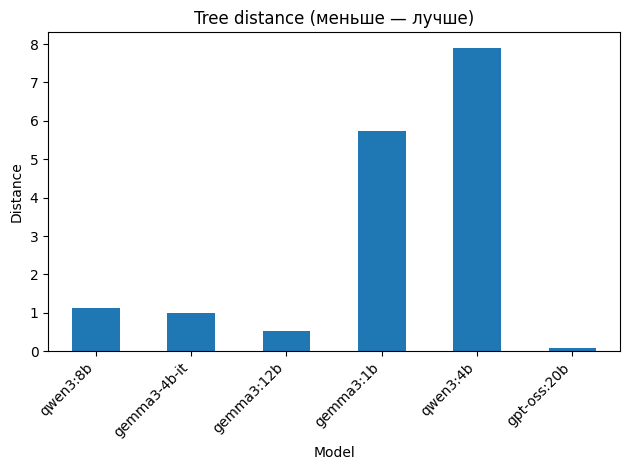

In [53]:
import matplotlib.pyplot as plt
import pandas as pd

metrics_data = summed_metrics

df = pd.DataFrame(metrics_data).T

# нормализуем метрики (делим на 11 документов там, где это счётчики)
count_metrics = [
    'valid_json','recall_keys','precision_keys','f1_keys',
    'accuracy_values','items_recall','items_precision',
    'items_accuracy','document_match_pct','seller_match_pct','buyer_match_pct'
]

df_norm = df.copy()
df_norm[count_metrics] = df_norm[count_metrics] / 11.0

# 1. Срравнение главных полей
plt.figure()
df_norm[['document_match_pct','seller_match_pct','buyer_match_pct']].plot(kind='bar')
plt.title('Совпадения важных полей (доля от 1)')
plt.ylabel('Match %')
plt.xlabel('Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 2. Качество стркутуры JSON
plt.figure()
df_norm[['recall_keys','precision_keys','f1_keys','accuracy_values']].plot(kind='bar')
plt.title('Качество структуры JSON')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Таблица
plt.figure()
df_norm[['items_recall','items_precision','items_accuracy']].plot(kind='bar')
plt.title('Качество извлечения items')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Дистанция дерева
plt.figure()
df['tree_distance'].plot(kind='bar')
plt.title('Tree distance (меньше — лучше)')
plt.ylabel('Distance')
plt.xlabel('Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## Выводы по метрикам.

Модели показали неплохие метрики распознования. При детальном анализе конкретных ошибок видно, что модели часто ошибаются в формате вывода (например .руб вместо РУБ), что легко можно исправить маппингом или словарем знначений. Но, модели также ошибаются в опредлении точных дат и переодически ошибаются в опредлении некотрых полей. В текущем виде модели могут использоваться только в полуавтоматическом режиме с проверкой праввильности ввода пользователем. Возможно, использование более сильных моделей решило бы проблему с точностью.